# CFM 301 Project 5: Comparing Mutual Funds — Are the Fees Justified?

**Four active US large-cap growth funds vs. factor models and low-cost index funds, July 1993 – December 2025**

## 1. Economic question and intended audience (requirement 1)

**Question.** Do four of the largest actively managed US large-cap growth funds earn a gross-of-fee alpha large
enough to leave their investors a non-negative net-of-fee alpha? We measure alpha against factor models (CAPM,
Fama-French 3, Carhart 4) and against a portfolio of low-cost Vanguard index funds that an investor could actually buy.

| Fund | Ticker | Share class |
|---|---|---|
| Fidelity Contrafund | FCNTX | Retail, no load |
| T. Rowe Price Blue Chip Growth | TRBCX | Investor class, no load |
| American Funds Growth Fund of America | AGTHX | Class A (front-end load up to 5.75%) |
| Fidelity Magellan | FMAGX | Retail, no load |

**Intended audience.** Retail investors and the financial advisors who choose funds for them. They pay the fee, they
choose between these funds and index funds, and they cannot short factor portfolios, so the index-fund benchmark is the
alternative that matters most to them. **Who would fund this analysis:** investor-advocacy organizations and
robo-advisors that recommend low-cost portfolios, and securities regulators (the SEC, the Ontario Securities
Commission) that review fee disclosure.

**Motivation.** Together these four funds manage over $600 billion and charge 0.6–0.8% a year, about four times a
growth index fund. If their gross alpha does not cover that fee, investors are paying for exposures they could buy
cheaply.

## 2. Setup

**How to run (reproducibility).**
1. Keep this structure: `mutualfunds.ipynb` next to a `Data/` folder with the CSV files listed in §3.
2. Open the notebook from the `Mutual Funds` folder (or from the repository root; both work) and choose
   **Restart & Run All**.
3. The notebook reads only local files with relative paths. It needs no WRDS login, no internet connection and no
   manual steps. It writes every table (`output/*.csv`) and figure (`output/fig*.png`) used in the report.
   Runtime: about a minute.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import scipy
import statsmodels
import statsmodels.api as sm
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import spearmanr
from IPython.display import display

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | statsmodels "
      f"{statsmodels.__version__} | scipy {scipy.__version__} | matplotlib {matplotlib.__version__}")

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Works whether the notebook is started from its own folder or from the repository root
DATA = Path("Data") if Path("Data").exists() else Path("Mutual Funds") / "Data"
OUT = DATA.parent / "output"
OUT.mkdir(exist_ok=True)

ACTIVE = ["FCNTX", "TRBCX", "AGTHX", "FMAGX"]
INDEX = ["VFINX", "NAESX", "VIVAX", "VIGRX"]
NAMES = {"FCNTX": "Fidelity Contrafund", "TRBCX": "T. Rowe Price Blue Chip Growth",
         "AGTHX": "Growth Fund of America A", "FMAGX": "Fidelity Magellan",
         "VFINX": "Vanguard 500 Index", "NAESX": "Vanguard Small-Cap Index",
         "VIVAX": "Vanguard Value Index", "VIGRX": "Vanguard Growth Index"}
MODELS = {"CAPM": ["mktrf"], "FF3": ["mktrf", "smb", "hml"], "Carhart": ["mktrf", "smb", "hml", "umd"]}
NW_LAGS = 6                      # Newey-West lags for monthly return regressions
AGTHX_LOAD = 0.0575              # maximum Class A front-end sales charge

Python 3.11.9 | pandas 2.2.3 | numpy 2.4.6 | statsmodels 0.15.0 | scipy 1.17.1 | matplotlib 3.11.2


### Helper functions

Regressions use OLS with **Newey-West (HAC)** standard errors (statsmodels). Monthly fund returns have little
autocorrelation, but their residuals are heteroskedastic (volatile in crises), so plain OLS t-statistics would be too
optimistic. Tracking error is the standard deviation of the regression residual (regression tracking error, Ch. 10,
slides 17–18), and the information (appraisal) ratio is alpha / tracking error.

In [2]:
def ols_hac(y, X, lags=NW_LAGS):
    """OLS of y on [1, X] with Newey-West (HAC) standard errors."""
    return sm.OLS(y, sm.add_constant(X), missing="drop").fit(cov_type="HAC", cov_kwds={"maxlags": lags})


def factor_fit(y, X):
    """Annualized alpha (x12), its t-stat, tracking error (resid. sd x sqrt 12), IR, R2 and loadings."""
    m = ols_hac(y, X)
    te = m.resid.std(ddof=X.shape[1] + 1)
    out = {"alpha": m.params["const"] * 12, "t": m.tvalues["const"], "TE": te * np.sqrt(12),
           "IR": m.params["const"] * 12 / (te * np.sqrt(12)), "R2": m.rsquared, "n": int(m.nobs)}
    out.update({f"b_{k}": v for k, v in m.params.drop("const").items()})
    return out


def winsorize(s, lo, hi):
    return s.clip(s.quantile(lo), s.quantile(hi))


def save_table(df, name):
    """Save a table used in the report to output/ and return it for display."""
    df.to_csv(OUT / f"{name}.csv")
    return df

## 3. Fund selection and data sources (requirement 2)

**Selection.** Four large, long-lived actively managed funds in the same Morningstar category (US large-cap growth), so
their performance is comparable, plus four Vanguard index funds as the implementable benchmark. We do not have WRDS
access to the CRSP Mutual Fund Database, so all data come from free public sources. `pull_data.py` downloaded them once and
merged them into `panel_monthly.csv` (one row per fund-month); this notebook only reads the four CSV files in `Data/`.

| Data | File in `Data/` | Source | Coverage |
|---|---|---|---|
| Daily NAV, dividends, capital gains → monthly total returns | `panel_monthly.csv` | Yahoo Finance | 1993–2025 |
| Corrections to 6 Yahoo distributions | `distribution_corrections.csv` | SEC Form N-SAR item 73 (distributions per share) | 1993–2002 |
| Mkt-RF, SMB, HML, UMD, risk-free rate | in `panel_monthly.csv` | Kenneth French Data Library | 1993–2025 |
| Expense ratio per fiscal year | in `panel_monthly.csv` | SEC prospectus risk/return data sets (2010+); SEC Form N-SAR expenses ÷ average net assets (1993–2009) | 1993–2025 |
| Portfolio turnover | in `panel_monthly.csv` | SEC N-SAR item 71D; prospectus data | 1993–2025 |
| Monthly sales and redemptions; total net assets (TNA) | in `panel_monthly.csv` | SEC Forms N-SAR (semi-annual, to 2018) and N-PORT (quarterly, 2019+) | 1993–2025 |
| Official monthly fund returns (check) | `nport_class_returns.csv` | SEC Form N-PORT | 2019–2025 |
| 2025 expense ratio of every US fund share class | `fee_distribution_all_funds_2025.csv` | SEC prospectus risk/return data sets | 2025 |

In [3]:
raw = pd.read_csv(DATA / "panel_monthly.csv", parse_dates=["date"])
corr = pd.read_csv(DATA / "distribution_corrections.csv", parse_dates=["date"])
print(f"panel_monthly.csv: {len(raw):,} fund-months, {raw['ticker'].nunique()} funds, "
      f"{raw['date'].min():%Y-%m} to {raw['date'].max():%Y-%m}")
raw.groupby("ticker")["date"].agg(["min", "max", "count"])

panel_monthly.csv: 3,155 fund-months, 8 funds, 1993-02 to 2025-12


,min,max,count
ticker,,,
AGTHX,1993-02-28,2025-12-31,395
FCNTX,1993-02-28,2025-12-31,395
FMAGX,1993-02-28,2025-12-31,395
NAESX,1993-02-28,2025-12-31,395
TRBCX,1993-07-31,2025-12-31,390
VFINX,1993-02-28,2025-12-31,395
VIGRX,1993-02-28,2025-12-31,395
VIVAX,1993-02-28,2025-12-31,395


## 4. Return construction (requirement 3)

- **Return variable:** `ret` = total return with all distributions reinvested,
  r(t) = (NAV(t) + dividends(t) + capital gains(t)) / NAV(t−1) − 1, computed daily from NAV and the distributions on
  each ex-date, and compounded to months. NAV returns are already net of the fund's expenses (they are what investors
  earned), so `ret` is the **net-of-fee** return.
- **Share class:** one class per fund, the retail class an individual investor buys. FCNTX, FMAGX and TRBCX are
  no-load; AGTHX is Class A, whose front-end load is not in NAV returns or the expense ratio (tested in §11). We do
  not combine share classes at the fund level: class-level returns and TNA for every class are not available from free
  data, and the retail class is the relevant one for our audience.
- **Fees:** each fiscal year's annual expense ratio is converted to the monthly frequency of our returns as fee / 12.
  Gross return = net return + fee / 12.
- **Excess returns:** every factor regression uses returns minus the one-month T-bill rate (`rf`).

In [4]:
p = raw.copy()
p["exp_monthly"] = p["exp_ratio"] / 12                     # annual expense ratio -> monthly
p["exret"] = p["ret"] - p["rf"]                            # net-of-fee excess return
p["exret_gross"] = p["ret"] + p["exp_monthly"] - p["rf"]   # gross: add back the monthly expense ratio
p[p["ticker"] == "FCNTX"][["date", "ret", "exp_ratio", "exp_monthly", "rf", "exret", "exret_gross"]].tail(3)

,date,ret,exp_ratio,exp_monthly,rf,exret,exret_gross
392,2025-10-31,0.010097,0.0074,0.000617,0.0037,0.006397,0.007014
393,2025-11-30,-0.000800,0.0074,0.000617,0.0030,-0.003800,-0.003183
394,2025-12-31,0.016607,0.0074,0.000617,0.0034,0.013207,0.013824


## 5. Data cleaning (requirement 4)

Each step is applied to the whole panel, and the cleaning log at the end of this section counts the observations
each step affects.

1. **Common sample:** every fund must have data for the same months, so the sample starts at TRBCX's inception
   (July 1993).
2. **Duplicates:** fund-months that appear twice are dropped.
3. **Missing returns or factors:** dropped (not filled).
4. **Distribution errors:** Yahoo's dividends and capital gains are checked against the per-share distributions each
   fund reported to the SEC (N-SAR item 73) and the price move on each ex-date; errors are corrected in
   `distribution_corrections.csv`. The corrections are already applied to the returns in
   `panel_monthly.csv`; the file documents each one and its evidence.
5. **Missing expense ratios:** years with no fee filing are interpolated between adjacent years or carried from the
   nearest year. The same is done for turnover.
6. **Missing flows:** months with no reported sales and redemptions (mainly April 2018 – June 2019, between the last
   N-SAR and first N-PORT filing) are handled in the TNA construction (§10).
7. **Outliers:** flagged (|monthly return| > 25%, and residuals beyond 4 standard deviations), not removed.

In [5]:
steps = [("Fund-months in panel_monthly.csv (8 funds)", len(p), "")]
start = p.groupby("ticker")["date"].min().max()            # latest fund start (TRBCX)
n0 = len(p)
p = p[p["date"] >= start].copy()
steps.append((f"1. Common sample from {start:%Y-%m} (TRBCX inception)", len(p), f"dropped {n0 - len(p)}"))

dups = int(p.duplicated(["ticker", "date"]).sum())
p = p.drop_duplicates(["ticker", "date"])
steps.append(("2. Duplicate fund-months removed", len(p), f"{dups}"))

miss = int(p[["ret", "mktrf", "smb", "hml", "umd", "rf"]].isna().any(axis=1).sum())
p = p.dropna(subset=["ret", "mktrf", "smb", "hml", "umd", "rf"])
steps.append(("3. Months missing a return or factor removed", len(p), f"{miss}"))

steps.append(("4. Distributions corrected (Yahoo vs SEC N-SAR item 73)", len(p),
              f"{len(corr)} events, {corr['ticker'].nunique()} funds"))
act = p[p["ticker"].isin(ACTIVE)]
fee_fill = int(act["exp_source"].isin(["filled", "carried"]).sum())
to_fill = int(act["turnover_source"].isin(["filled", "carried"]).sum())
steps.append(("5a. Active fund-months with expense ratio filled/carried", len(p), f"{fee_fill} of {len(act)}"))
steps.append(("5b. Active fund-months with turnover filled/carried", len(p), f"{to_fill} of {len(act)}"))
steps.append(("6. Active fund-months with no reported flow (see §10)", len(p), f"{int(act['net_flow'].isna().sum())} of {len(act)}"))
big = int((p["ret"].abs() > 0.25).sum())
steps.append(("7. Outliers: |monthly return| > 25% (kept)", len(p), f"{big}"))

wide = p.pivot(index="date", columns="ticker", values="ret")
ff = p.drop_duplicates("date").set_index("date")[["mktrf", "smb", "hml", "umd", "rf"]]
print(f"Sample: {p['date'].min():%Y-%m} to {p['date'].max():%Y-%m}, {p['date'].nunique()} months")
display(corr)

Sample: 1993-07 to 2025-12, 390 months


,ticker,date,amount,reason
0,AGTHX,1993-12-15,0.2725,Yahoo records half the payout (all AGTHX distr...
1,AGTHX,1994-12-21,0.3025,SEC N-SAR item 73 FY1995: $1.21/share = $0.605...
2,AGTHX,1995-12-20,0.6400,SEC N-SAR item 73 FY1996: $2.56/share = $1.28 ...
3,TRBCX,1994-12-28,0.1100,SEC N-SAR item 73 FY1994: $0.22/share; Yahoo h...
4,TRBCX,1995-12-27,0.0800,SEC N-SAR item 73 FY1995: $0.23/share; Yahoo h...
5,FCNTX,2002-06-07,-0.2300,Spurious: NAV did not drop on the ex-date; SEC...


### Checking the return construction

Since 2019 every fund reports its official monthly return on Form N-PORT. Our returns, built from NAV and
distributions, should match them closely.

In [6]:
nport = pd.read_csv(DATA / "nport_class_returns.csv", parse_dates=["date"])
chk = p.merge(nport, on=["ticker", "date"])
chk["diff_pp"] = (chk["ret"] - chk["ret_pct"] / 100).abs() * 100
ret_check = save_table(chk.groupby("ticker")["diff_pp"].agg(months="size", median_abs_diff="median",
                                                            max_abs_diff="max"), "check_nport")
print("Our monthly total return vs the fund-reported N-PORT return (percentage points):")
ret_check.round(4)

Our monthly total return vs the fund-reported N-PORT return (percentage points):


,months,median_abs_diff,max_abs_diff
ticker,,,
AGTHX,76,0.0013,0.0047
FCNTX,78,0.0020,0.0560
FMAGX,78,0.0024,0.1083
TRBCX,78,0.0030,0.0050


### Outliers and the winsorization decision

We flag fund-months with |return| > 25% and Carhart residuals beyond 4 standard deviations. **We do not winsorize in
the baseline.** These are diversified portfolios of hundreds of stocks, so extreme months (October 2008, March 2020)
are real market moves, not data errors, and clipping them would change each fund's measured beta and alpha. §11 shows
the results with returns winsorized at 1%/99%, so the effect can be judged.

In [7]:
flags = []
for t in ACTIVE:
    g = p[p["ticker"] == t].set_index("date")
    m = ols_hac(g["exret"], g[MODELS["Carhart"]])
    z = m.resid / m.resid.std()
    for d, v in z[z.abs() > 4].items():
        flags.append({"fund": t, "month": f"{d:%Y-%m}", "return": g.loc[d, "ret"], "residual z": v})
flags = pd.DataFrame(flags)
steps.append(("7b. Carhart residuals beyond 4 sd (flagged, kept)", len(p), f"{len(flags)}"))
display(flags.round(3) if len(flags) else "none")

,fund,month,return,residual z
0,AGTHX,2000-02,0.137,5.546
1,FMAGX,2008-09,-0.180,-5.584


### Cleaning log

In [8]:
cleaning = save_table(pd.DataFrame(steps, columns=["step", "rows after", "affected"]).set_index("step"), "table0_cleaning")
cleaning

,rows after,affected
step,,
Fund-months in panel_monthly.csv (8 funds),3155,
1. Common sample from 1993-07 (TRBCX inception),3120,dropped 35
2. Duplicate fund-months removed,3120,0
3. Months missing a return or factor removed,3120,0
4. Distributions corrected (Yahoo vs SEC N-SAR item 73),3120,"6 events, 3 funds"
5a. Active fund-months with expense ratio filled/carried,3120,192 of 1560
5b. Active fund-months with turnover filled/carried,3120,96 of 1560
6. Active fund-months with no reported flow (see §10),3120,98 of 1560
7. Outliers: |monthly return| > 25% (kept),3120,0


**What the cleaning shows.** The panel is complete: no duplicates and no missing returns or factors in the common
sample, and no month moves more than 25%. The main data problems were in Yahoo's distribution records: AGTHX's
1993–95 distributions were recorded at half their size (understating its return by 2–4 percentage points a year),
TRBCX's 1994–95 capital gains were short, and a spurious FCNTX distribution in June 2002 added 5.5% to one month.
After the corrections our returns match the funds' official N-PORT returns to a median of about 0.002 percentage
points. About 12% of active fund-months use an interpolated or carried expense ratio, mostly 2016 and 2023 (the SEC
published no data set for those filing years) and AGTHX 2006–09.

## 6. CAPM, Fama-French 3-factor and Carhart 4-factor alphas (requirement 5)

For each fund we regress the net-of-fee excess return on the market factor (CAPM), then add SMB and HML (FF3) and
momentum UMD (Carhart). Alpha and tracking error are annualized (alpha × 12, TE × √12, Ch. 10, slide 29).

In [9]:
rows = []
for t in ACTIVE:
    g = p[p["ticker"] == t].set_index("date")
    for mname, cols in MODELS.items():
        rows.append({"fund": t, "model": mname, **factor_fit(g["exret"], g[cols])})
reg = pd.DataFrame(rows).set_index(["fund", "model"])
table1 = reg[["alpha", "t", "TE", "IR", "R2"]].copy()
table1[["alpha", "TE"]] *= 100
save_table(table1.round(3), "table1_factor_regressions")
print("Table 1. Net-of-fee alpha (%/yr), Newey-West t, tracking error (%/yr), information ratio, R2")
table1.round(2)

Table 1. Net-of-fee alpha (%/yr), Newey-West t, tracking error (%/yr), information ratio, R2


alpha     t    TE    IR    R2
fund  model                                 
FCNTX CAPM      2.75  2.81  5.68  0.48  0.85
      FF3       3.03  3.35  5.46  0.55  0.86
      Carhart   1.69  1.88  4.83  0.35  0.89
TRBCX CAPM      0.99  0.85  5.42  0.18  0.89
      FF3       1.36  1.47  4.48  0.30  0.93
      Carhart   1.32  1.41  4.49  0.29  0.93
AGTHX CAPM      1.17  1.10  4.84  0.24  0.91
      FF3       1.69  1.72  4.15  0.41  0.94
      Carhart   1.68  1.78  4.16  0.40  0.94
FMAGX CAPM     -1.49 -1.31  5.00 -0.30  0.91
      FF3      -1.36 -1.26  4.69 -0.29  0.92
      Carhart  -1.48 -1.32  4.69 -0.32  0.92

In [10]:
print("Factor loadings (net returns):")
display(reg[["b_mktrf", "b_smb", "b_hml", "b_umd"]].round(2))
print("Average factor premiums over the sample, %/yr:")
(ff[["mktrf", "smb", "hml", "umd"]].mean() * 1200).round(2)

Factor loadings (net returns):


b_mktrf  b_smb  b_hml  b_umd
fund  model                                
FCNTX CAPM        0.87    NaN    NaN    NaN
      FF3         0.86  -0.03  -0.14    NaN
      Carhart     0.92  -0.03  -0.09   0.17
TRBCX CAPM        1.03    NaN    NaN    NaN
      FF3         1.03  -0.15  -0.25    NaN
      Carhart     1.04  -0.15  -0.25   0.01
AGTHX CAPM        1.01    NaN    NaN    NaN
      FF3         0.98   0.11  -0.18    NaN
      Carhart     0.98   0.11  -0.18   0.00
FMAGX CAPM        1.05    NaN    NaN    NaN
      FF3         1.06  -0.12  -0.13    NaN
      Carhart     1.06  -0.12  -0.12   0.01

Average factor premiums over the sample, %/yr:


mktrf    9.10
smb      0.40
hml      1.52
umd      4.29
dtype: float64

### What the regressions show: how and why alpha changes as factors are added

- **CAPM → FF3: alpha rises for every fund.** All four funds load negatively on HML (−0.09 to −0.25): they hold growth
  stocks. Value beat growth on average over 1993–2025 (HML premium about +1.5%/yr), so the FF3 benchmark expects a
  growth fund to earn *less* than the CAPM does. Adding SMB and HML therefore raises alpha (e.g. AGTHX +1.17% → +1.69%,
  TRBCX +0.99% → +1.36%) and lowers tracking error: these managers beat the market despite a style that lagged.
- **FF3 → Carhart: only Contrafund changes.** Contrafund loads +0.17 on momentum, and momentum earned about +4.3%/yr,
  so part of its FF3 alpha (+3.03%) was momentum exposure; its Carhart alpha falls to +1.69%. This is the pattern in
  the Berkshire Hathaway example (Ch. 10, slides 26–40) and in Carhart (1997) (Ch. 16, slide 23): momentum explains a
  large part of the apparent skill of winning funds. The other three funds have UMD loadings near zero.
- **Net alphas** are +1.3% to +1.7% a year for FCNTX, TRBCX and AGTHX (t = 1.4–1.9, marginal) and −1.5% for Magellan,
  negative under every model. R² is 0.89–0.94: these funds are mostly market exposure.

## 7. Gross vs. net alpha (requirement 6)

Following Wermers (2000) and Fama and French (2010) (Ch. 16, slides 20–21), we compute alpha twice: on reported (net)
returns, and on gross returns that add back that year's expense ratio / 12. The difference is the fee investors paid.

In [11]:
def alphas_gross_net(data, cols=MODELS["Carhart"]):
    out = {}
    for t in ACTIVE:
        g = data[data["ticker"] == t].set_index("date")
        n, gr = factor_fit(g["exret"], g[cols]), factor_fit(g["exret_gross"], g[cols])
        out[t] = {"fee": g["exp_ratio"].mean() * 100, "gross_alpha": gr["alpha"] * 100, "t_gross": gr["t"],
                  "net_alpha": n["alpha"] * 100, "t_net": n["t"]}
    return pd.DataFrame(out).T


gn = {m: alphas_gross_net(p, cols) for m, cols in MODELS.items()}
gn_all = pd.concat({m: d[["gross_alpha", "t_gross", "net_alpha", "t_net"]] for m, d in gn.items()}, axis=1)
save_table(gn_all.round(3), "table_gross_net_all_models")
gn_all.round(2)

CAPM                                 FF3                             Carhart                        
      gross_alpha t_gross net_alpha t_net gross_alpha t_gross net_alpha t_net gross_alpha t_gross net_alpha t_net
FCNTX        3.56    3.63      2.75  2.81        3.84    4.24      3.03  3.35        2.50    2.78      1.69  1.88
TRBCX        1.83    1.57      0.99  0.85        2.20    2.36      1.36  1.47        2.15    2.29      1.32  1.41
AGTHX        1.87    1.75      1.17  1.10        2.39    2.43      1.69  1.72        2.37    2.53      1.68  1.78
FMAGX       -0.79   -0.69     -1.49 -1.31       -0.66   -0.61     -1.36 -1.26       -0.78   -0.69     -1.48 -1.32

**What gross vs. net shows.** Under the Carhart model, FCNTX, TRBCX and AGTHX earn gross alphas of 2.2–2.5% a year
(t = 2.3–2.8): evidence of stock-picking skill before fees. Fees of 0.7–0.8% a year take about a third of it, and the
remaining net alphas are only marginally significant. Magellan has a negative gross alpha (−0.78%): its managers did
not add value even before fees, so no fee is justified.

## 8. Implementable benchmark: low-cost index funds (requirement 7)

Following the Berkshire Hathaway example (Ch. 10, slides 31–34), we regress each fund's return on the returns of four
Vanguard index funds (500 Index, Small-Cap, Value, Growth), **constraining the weights to be non-negative and to sum
to one**, with an intercept. The index funds' returns are net of their own low fees, so the fitted benchmark is a
portfolio an investor could actually hold, and the intercept is the fund's alpha against it. We solve the constrained
least-squares problem with SLSQP; the alpha's t-statistic uses Newey-West errors on the residual return.

In [12]:
def constrained_benchmark(y, X):
    """min sum (y - a - X w)^2  s.t. w >= 0, sum(w) = 1. Returns weights and fund-minus-benchmark returns."""
    k = X.shape[1]
    res = minimize(lambda v: np.sum((y - v[0] - X @ v[1:]) ** 2), np.r_[0.0, np.full(k, 1 / k)], method="SLSQP",
                   bounds=[(None, None)] + [(0, 1)] * k,
                   constraints=[{"type": "eq", "fun": lambda v: v[1:].sum() - 1}],
                   options={"ftol": 1e-14, "maxiter": 1000})
    w = res.x[1:]
    return w, y - X @ w


index_fee = p[p["ticker"].isin(INDEX)].groupby("ticker")["exp_ratio"].mean()
bench_rows = []
for t in ACTIVE:
    g = p[p["ticker"] == t].set_index("date")
    X = wide.loc[g.index, INDEX].values
    for kind, y in [("net", g["ret"].values), ("gross", (g["ret"] + g["exp_monthly"]).values)]:
        w, active_ret = constrained_benchmark(y, X)
        m = sm.OLS(active_ret, np.ones(len(active_ret))).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
        te = (active_ret - active_ret.mean()).std(ddof=len(INDEX)) * np.sqrt(12)
        r2 = 1 - np.sum((active_ret - active_ret.mean()) ** 2) / np.sum((y - y.mean()) ** 2)
        bench_rows.append({"fund": t, "returns": kind, "alpha": m.params[0] * 1200, "t": m.tvalues[0],
                           "TE": te * 100, "IR": m.params[0] * 12 / te, "R2": r2,
                           **{f"w_{i}": wi for i, wi in zip(INDEX, w)},
                           "bench_fee": float(np.dot(w, index_fee[INDEX])) * 100})
bench = pd.DataFrame(bench_rows).set_index(["fund", "returns"])
save_table(bench.round(4), "table_index_benchmark")
print("Average index-fund expense ratios over the sample, %:", (index_fee * 100).round(3).to_dict())
bench.round(3)

Average index-fund expense ratios over the sample, %: {'NAESX': 0.257, 'VFINX': 0.161, 'VIGRX': 0.229, 'VIVAX': 0.229}


alpha      t     TE     IR     R2  w_VFINX  w_NAESX  w_VIVAX  w_VIGRX  bench_fee
fund  returns                                                                                  
FCNTX net      1.190  1.335  5.926  0.201  0.834    0.264    0.153    0.055    0.528      0.215
      gross    1.999  2.238  5.927  0.337  0.834    0.257    0.153    0.058    0.531      0.216
TRBCX net      0.485  0.582  4.067  0.119  0.941    0.000    0.058    0.080    0.861      0.230
      gross    1.317  1.582  4.065  0.324  0.941    0.000    0.058    0.080    0.861      0.230
AGTHX net      0.810  0.862  4.444  0.182  0.926    0.000    0.311    0.057    0.632      0.237
      gross    1.506  1.602  4.444  0.339  0.926    0.000    0.311    0.057    0.632      0.237
FMAGX net     -1.478 -1.488  4.579 -0.323  0.926    0.000    0.107    0.211    0.682      0.232
      gross   -0.779 -0.785  4.579 -0.170  0.926    0.000    0.107    0.211    0.682      0.232

In [13]:
fees_2025 = p[p["date"].dt.year == 2025].groupby("ticker")["exp_ratio"].last() * 100
table2 = pd.DataFrame({
    "fee_avg": gn["Carhart"]["fee"], "fee_2025": fees_2025[ACTIVE],
    "gross_alpha": gn["Carhart"]["gross_alpha"], "t_gross": gn["Carhart"]["t_gross"],
    "net_alpha": gn["Carhart"]["net_alpha"], "t_net": gn["Carhart"]["t_net"],
    "index_alpha": bench.xs("net", level="returns")["alpha"], "t_index": bench.xs("net", level="returns")["t"],
    "bench_fee": bench.xs("net", level="returns")["bench_fee"],
})
table2["fee_saving"] = table2["fee_avg"] - table2["bench_fee"]


def verdict(gross, net):
    """Fee justified = positive gross alpha that still leaves a non-negative net alpha."""
    if gross <= 0:
        return "Not justified (no gross alpha)"
    return "Justified" if net >= 0 else "Not justified (fee > gross alpha)"


table2["verdict"] = [verdict(g, n) for g, n in zip(table2["gross_alpha"], table2["net_alpha"])]
save_table(table2.round(3), "table2_fees_gross_net_index")
print("Table 2. Fees, Carhart gross/net alpha and index-benchmark alpha (%/yr)")
table2.round(2)

Table 2. Fees, Carhart gross/net alpha and index-benchmark alpha (%/yr)


,fee_avg,fee_2025,gross_alpha,t_gross,net_alpha,t_net,index_alpha,t_index,bench_fee,fee_saving,verdict
FCNTX,0.81,0.74,2.50,2.78,1.69,1.88,1.19,1.34,0.22,0.59,Justified
TRBCX,0.83,0.70,2.15,2.29,1.32,1.41,0.48,0.58,0.23,0.60,Justified
AGTHX,0.70,0.59,2.37,2.53,1.68,1.78,0.81,0.86,0.24,0.46,Justified
FMAGX,0.70,0.64,-0.78,-0.69,-1.48,-1.32,-1.48,-1.49,0.23,0.47,Not justified (no gross alpha)


**What the index-fund benchmark shows.** The constrained regression puts 53–86% of every fund in the Vanguard Growth
Index, and a mix of index funds explains 83–94% of each fund's return variance. That mix costs only 0.21–0.24% a year,
against 0.70–0.83% for the active funds: **an investor could have bought the same exposures for 0.46–0.60% a year
less**. Against this benchmark, net alphas shrink to +0.48% (TRBCX), +0.81% (AGTHX) and +1.19% (FCNTX), and none is
statistically significant (t ≤ 1.3). Magellan stays at −1.48%.

## 9. Fees and turnover vs. performance (requirement 8)

**Across funds.** Do the higher-fee funds deliver enough extra gross alpha to cover their higher fee? With four funds
this is a comparison, not a test.

In [14]:
xf = table2[["fee_avg", "gross_alpha", "net_alpha"]].join(
    p[p["ticker"].isin(ACTIVE)].groupby("ticker")["turnover"].mean().mul(100).rename("turnover_avg")).sort_values("fee_avg")
hi_fee = xf["fee_avg"] > xf["fee_avg"].median()
fee_compare = save_table(pd.DataFrame({
    "funds": [", ".join(xf.index[hi_fee]), ", ".join(xf.index[~hi_fee])],
    "avg fee": [xf.loc[hi_fee, "fee_avg"].mean(), xf.loc[~hi_fee, "fee_avg"].mean()],
    "avg gross alpha": [xf.loc[hi_fee, "gross_alpha"].mean(), xf.loc[~hi_fee, "gross_alpha"].mean()],
    "avg net alpha": [xf.loc[hi_fee, "net_alpha"].mean(), xf.loc[~hi_fee, "net_alpha"].mean()],
}, index=["higher-fee pair", "lower-fee pair"]), "table_fee_groups")
display(xf.round(2))
fee_compare.round(2)

,fee_avg,gross_alpha,net_alpha,turnover_avg
AGTHX,0.70,2.37,1.68,29.97
FMAGX,0.70,-0.78,-1.48,63.69
FCNTX,0.81,2.50,1.69,81.97
TRBCX,0.83,2.15,1.32,36.30


,funds,avg fee,avg gross alpha,avg net alpha
higher-fee pair,"FCNTX, TRBCX",0.82,2.33,1.5
lower-fee pair,"AGTHX, FMAGX",0.70,0.80,0.1


**Within funds over time (in the spirit of Carhart 1997, Ch. 16, slide 22).** Each fund-year's abnormal return is the
sum over the year of (excess return − Carhart loadings × factors), using the fund's full-sample loadings. We regress
gross and net abnormal returns on that year's expense ratio and turnover, using only fund-years where both were
observed (not filled or carried). Fees and alphas both drifted down over 1993–2025, so the last specification adds a
time trend.

In [15]:
abn = []
for t in ACTIVE:
    g = p[p["ticker"] == t].set_index("date").copy()
    cols = MODELS["Carhart"]
    for kind, y in [("net", "exret"), ("gross", "exret_gross")]:
        m = ols_hac(g[y], g[cols])
        g[f"abn_{kind}"] = g[y] - g[cols] @ m.params[cols]
    yr = g.assign(year=g.index.year).groupby("year").agg(abn_net=("abn_net", "sum"), abn_gross=("abn_gross", "sum"),
                                                         fee=("exp_ratio", "mean"), turnover=("turnover", "mean"),
                                                         fee_src=("exp_source", "first"),
                                                         to_src=("turnover_source", "first"), months=("ret", "size"))
    abn.append(yr.assign(ticker=t))
fy = pd.concat(abn).reset_index()
fy = fy[(fy["months"] == 12) & ~fy["fee_src"].isin(["filled", "carried"]) & ~fy["to_src"].isin(["filled", "carried"])]
print(f"Fund-years with observed fee and turnover: {len(fy)}")
carhart_rows = []
for kind in ["gross", "net"]:
    for spec in ["pooled", "fund FE", "fund FE + trend"]:
        X = fy[["fee", "turnover"]].copy()
        if spec != "pooled":
            X = X.join(pd.get_dummies(fy["ticker"], drop_first=True, dtype=float))
        if spec == "fund FE + trend":
            X["year"] = fy["year"] - fy["year"].mean()
        m = sm.OLS(fy[f"abn_{kind}"], sm.add_constant(X)).fit(cov_type="HC1")
        carhart_rows.append({"returns": kind, "spec": spec, "b_fee": m.params["fee"], "t_fee": m.tvalues["fee"],
                             "b_turnover": m.params["turnover"], "t_turnover": m.tvalues["turnover"], "n": int(m.nobs)})
carhart_tab = save_table(pd.DataFrame(carhart_rows).set_index(["returns", "spec"]), "table_fee_turnover_regression")
print("b_fee: change in annual abnormal return per 1.00 (= 100 pp) of expense ratio; "
      "b_turnover: per 1.00 (= 100%) of turnover")
carhart_tab.round(3)

Fund-years with observed fee and turnover: 113
b_fee: change in annual abnormal return per 1.00 (= 100 pp) of expense ratio; b_turnover: per 1.00 (= 100%) of turnover


b_fee  t_fee  b_turnover  t_turnover    n
returns spec                                                      
gross   pooled           9.038  2.447      -0.019      -1.957  113
        fund FE          8.463  2.095      -0.020      -1.804  113
        fund FE + trend  5.817  1.230      -0.027      -2.313  113
net     pooled           8.052  2.180      -0.019      -1.962  113
        fund FE          7.480  1.852      -0.020      -1.807  113
        fund FE + trend  4.835  1.023      -0.027      -2.315  113

**Where each fee sits in the distribution of fund fees (Ch. 15, slide 36).** The SEC data set gives the 2025 expense
ratio of every US mutual fund share class. It has no fund-category field, so it includes bond and money-market funds;
we therefore also compare with the ICI equity-fund figures from lecture.

In [16]:
fee_dist = pd.read_csv(DATA / "fee_distribution_all_funds_2025.csv")["value"].dropna()
fee_dist = fee_dist[(fee_dist > 0) & (fee_dist < 0.05)]
ICI = {"Average equity fund (simple)": 1.09, "Average equity fund (asset-weighted)": 0.40,
       "Top 10% of growth funds": 1.75}          # ICI figures as cited in lecture
pct = {t: (fee_dist < fees_2025[t] / 100).mean() * 100 for t in ACTIVE + INDEX}
fee_place = pd.DataFrame({"fee_2025": fees_2025[ACTIVE + INDEX],
                          "percentile_all_US_fund_classes": pd.Series(pct),
                          "avg_turnover_%": p.groupby("ticker")["turnover"].mean()[ACTIVE + INDEX] * 100})
save_table(fee_place.round(2), "table_fee_distribution")
print(f"SEC 2025 fee distribution: {len(fee_dist):,} share classes, median {fee_dist.median()*100:.2f}%; ICI: {ICI}")
fee_place.round(2)

SEC 2025 fee distribution: 31,788 share classes, median 0.82%; ICI: {'Average equity fund (simple)': 1.09, 'Average equity fund (asset-weighted)': 0.4, 'Top 10% of growth funds': 1.75}


,fee_2025,percentile_all_US_fund_classes,avg_turnover_%
FCNTX,0.74,41.46,81.97
TRBCX,0.70,39.28,36.30
AGTHX,0.59,27.46,29.97
FMAGX,0.64,32.06,63.69
VFINX,0.14,3.19,4.05
NAESX,0.17,4.27,13.74
VIVAX,0.17,4.27,19.75
VIGRX,0.17,4.27,19.62


**What fees and turnover show.**
- **Across funds:** the two higher-fee funds (FCNTX, TRBCX, about 0.82%) earned more gross alpha than the two
  lower-fee funds (AGTHX, FMAGX, about 0.70%), so on average the extra 0.12% of fee was more than covered. But the gap
  comes entirely from Magellan's negative alpha: AGTHX, the cheapest fund, earned as much gross alpha as the
  more expensive ones. With four funds, fee level does not predict who earns alpha.
- **Within funds (Carhart 1997):** years with higher fees did *not* have lower gross abnormal returns. The fee
  coefficient is positive, but once the common downward trend in fees and alphas is removed it is insignificant
  (t ≈ 1.2). **Turnover hurts:** each 100 percentage points of turnover cost about 2.7% a year of abnormal return
  (t ≈ −2.3), consistent with trading costs.
- **Fee level:** the 2025 fees (0.59–0.74%) sit at the 27th–41st percentile of all US fund share classes (median
  0.82%) and below the ICI average equity-fund fee (1.09%), but well above the asset-weighted average (0.40%) and the
  index funds (0.14–0.17%, 3rd–4th percentile). These are cheap *active* funds, not cheap funds.

## 10. Persistence and flows (requirement 9)

### Persistence
We split the sample into two equal halves and compare Carhart alphas (Ch. 16, slide 23). With only four funds a rank
correlation is weak evidence, so we also test persistence *within* funds, using non-overlapping 36-month blocks.

In [17]:
dates = np.sort(p["date"].unique())
mid = dates[len(dates) // 2]
halves = {"first half": p[p["date"] < mid], "second half": p[p["date"] >= mid]}
half_tab = pd.concat({h: alphas_gross_net(d)[["gross_alpha", "t_gross", "net_alpha", "t_net"]] for h, d in halves.items()}, axis=1)
rho, pval = spearmanr(half_tab[("first half", "gross_alpha")], half_tab[("second half", "gross_alpha")])
print(f"Halves: {pd.Timestamp(dates[0]):%Y-%m} to {pd.Timestamp(mid) - pd.offsets.MonthEnd(1):%Y-%m} and "
      f"{pd.Timestamp(mid):%Y-%m} to {pd.Timestamp(dates[-1]):%Y-%m}; Spearman rank correlation of gross alpha = {rho:.2f} (n = 4)")
save_table(half_tab.round(3), "table3a_persistence_halves")
half_tab.round(2)

Halves: 1993-07 to 2009-09 and 2009-10 to 2025-12; Spearman rank correlation of gross alpha = 0.20 (n = 4)


first half                         second half                        
      gross_alpha t_gross net_alpha t_net gross_alpha t_gross net_alpha t_net
FCNTX        1.78    1.23      0.91  0.63        1.42    1.53      0.68  0.73
TRBCX        2.36    2.10      1.42  1.26        0.53    0.45     -0.19 -0.16
AGTHX        3.84    2.57      3.09  2.07        0.35    0.41     -0.29 -0.33
FMAGX       -0.34   -0.20     -1.08 -0.65       -1.98   -1.74     -2.63 -2.31

In [18]:
blocks = []
for t in ACTIVE:
    g = p[p["ticker"] == t].set_index("date")
    idx = np.arange(len(g)) // 36
    for b in np.unique(idx):
        gb = g[idx == b]
        if len(gb) == 36:
            blocks.append({"ticker": t, "block": b, "start": gb.index[0],
                           "alpha_gross": factor_fit(gb["exret_gross"], gb[MODELS["Carhart"]])["alpha"] * 100,
                           "alpha_net": factor_fit(gb["exret"], gb[MODELS["Carhart"]])["alpha"] * 100})
blocks = pd.DataFrame(blocks)
blocks["next_gross"] = blocks.groupby("ticker")["alpha_gross"].shift(-1)
pairs = blocks.dropna(subset=["next_gross"])
m = sm.OLS(pairs["next_gross"], sm.add_constant(pairs["alpha_gross"])).fit(cov_type="HC1")
persist_block = {"pairs": len(pairs), "slope": m.params["alpha_gross"], "t": m.tvalues["alpha_gross"],
                 "corr": pairs[["alpha_gross", "next_gross"]].corr().iloc[0, 1]}
print("Next 36-month gross alpha on this 36-month gross alpha (pooled):", {k: round(float(v), 3) for k, v in persist_block.items()})

Next 36-month gross alpha on this 36-month gross alpha (pooled): {'pairs': 36.0, 'slope': 0.181, 't': 1.215, 'corr': 0.191}


### Monthly TNA and fund flows

The assignment defines flow(t) = TNA(t) − TNA(t−1) × (1 + r(t)) (Ch. 16, slide 26), which needs **monthly** TNA. The
SEC reports TNA only semi-annually (N-SAR, to 2018) or quarterly (N-PORT, 2019+), and N-SAR's TNA field is blank in
years when a fund held more than $100 billion. The SEC does report each month's sales and redemptions. We therefore
build monthly TNA by rolling forward TNA(t) = TNA(t−1)(1 + r(t)) + net sales(t) from each reported TNA, and spread any
gap to the next reported TNA evenly (geometrically) across the months in between, so every reported TNA is matched
exactly. The size of that gap checks the data: it is the difference between the formula applied to two reported TNAs
and the SEC-reported net sales over the same months. Months with no reported sales (98 active fund-months) get zero
net sales in the roll-forward, and the gap spreads their flows across the period.

In [19]:
def monthly_tna(g):
    g = g.sort_values("date").reset_index(drop=True)
    r, F, rep = g["ret"].values, g["net_flow"].fillna(0).values, g["tna"].values
    T = np.full(len(g), np.nan)
    anchors = np.where(~np.isnan(rep))[0]
    gaps = []
    for a0, a1 in zip(anchors, list(anchors[1:]) + [len(g) - 1]):
        T[a0] = rep[a0]
        for k in range(a0 + 1, a1 + 1):
            T[k] = T[k - 1] * (1 + r[k]) + F[k]
        if not np.isnan(rep[a1]) and a1 > a0:
            ratio = rep[a1] / T[a1]
            gaps.append({"ticker": g["ticker"].iloc[0], "from": g["date"].iloc[a0], "to": g["date"].iloc[a1],
                         "months": a1 - a0, "gap_pct": (ratio - 1) * 100})
            for k in range(a0 + 1, a1 + 1):
                T[k] *= ratio ** ((k - a0) / (a1 - a0))
    return g.assign(tna_m=T), gaps


parts, gap_rows = [], []
for t in ACTIVE:
    gt, gaps_t = monthly_tna(p[p["ticker"] == t])
    parts.append(gt)
    gap_rows += gaps_t
fl = pd.concat(parts)
fl["flow"] = fl["tna_m"] - fl.groupby("ticker")["tna_m"].shift(1) * (1 + fl["ret"])
fl["flow_pct"] = fl["flow"] / fl.groupby("ticker")["tna_m"].shift(1)
fl["past12"] = fl.groupby("ticker")["ret"].transform(lambda s: (1 + s).rolling(12).apply(np.prod, raw=True).shift(1) - 1)
vf = p[p["ticker"] == "VFINX"].set_index("date")["ret"]
vf12 = ((1 + vf).rolling(12).apply(np.prod, raw=True) - 1).shift(1)
fl["past12_vs_sp500"] = fl["past12"] - fl["date"].map(vf12)
gaps = save_table(pd.DataFrame(gap_rows), "tna_rollforward_gaps")
print(f"Formula on reported TNA vs SEC-reported net sales: median |gap| {gaps['gap_pct'].abs().median():.2f}% of TNA "
      f"over {len(gaps)} reporting periods")
print("Periods longer than 12 months:")
print(gaps[gaps["months"] > 12].round(1).to_string(index=False))
p = p.merge(fl[["ticker", "date", "tna_m"]], on=["ticker", "date"], how="left")

Formula on reported TNA vs SEC-reported net sales: median |gap| 0.07% of TNA over 255 reporting periods
Periods longer than 12 months:
ticker       from         to  months  gap_pct
 FCNTX 2013-06-30 2019-09-30      75    -21.1
 TRBCX 2017-12-31 2019-09-30      21      0.5
 AGTHX 2005-02-28 2019-11-30     177     -9.5
 FMAGX 1999-09-30 2001-03-31      18     -0.2
 FMAGX 2018-03-31 2019-09-30      18    -12.9


In [20]:
f = fl.dropna(subset=["flow_pct", "past12"]).copy()
f["flow_pct_w"] = winsorize(f["flow_pct"], 0.01, 0.99)          # a few extreme flow months; winsorize 1%/99%
n_w = int((f["flow_pct"] != f["flow_pct_w"]).sum())
flow_rows = []
for xvar in ["past12", "past12_vs_sp500"]:
    X = pd.concat([f[[xvar]], pd.get_dummies(f["ticker"], drop_first=True, dtype=float)], axis=1)
    m = sm.OLS(f["flow_pct_w"] * 100, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    flow_rows.append({"past return": xvar, "slope (flow % per month per 1.00 past return)": m.params[xvar],
                      "t (NW 12)": m.tvalues[xvar], "R2": m.rsquared, "n": int(m.nobs)})
flow_tab = save_table(pd.DataFrame(flow_rows).set_index("past return"), "table3b_flows")
print(f"Flow % winsorized at 1%/99%: {n_w} fund-months changed")
f["bin"] = pd.qcut(f["past12_vs_sp500"], 5, labels=["Q1 worst", "Q2", "Q3", "Q4", "Q5 best"])
flow_bins = f.groupby("bin", observed=True).agg(past12_vs_sp500=("past12_vs_sp500", "mean"),
                                                avg_monthly_flow_pct=("flow_pct_w", "mean")).mul(100)
save_table(flow_bins.round(3), "table_flow_bins")
display(flow_tab.round(3))
flow_bins.round(2)

Flow % winsorized at 1%/99%: 32 fund-months changed


,slope (flow % per month per 1.00 past return),t (NW 12),R2,n
past return,,,,
past12,1.305,2.276,0.148,1504
past12_vs_sp500,2.483,1.777,0.138,1504


,past12_vs_sp500,avg_monthly_flow_pct
bin,,
Q1 worst,-7.99,-0.43
Q2,-2.25,-0.15
Q3,0.62,0.50
Q4,3.85,0.26
Q5 best,11.36,0.04


### Berk and Green (2004)

In Berk and Green's model (Ch. 16, slides 32–33), skilled managers attract inflows until diseconomies of scale and
fees leave investors with zero net alpha. If that is happening, alpha should fall as a fund grows. We regress each
36-month block's gross alpha on log TNA at the start of the block, with fund fixed effects.

In [21]:
blocks["tna_start"] = [p[(p["ticker"] == t) & (p["date"] == s)]["tna_m"].iloc[0] for t, s in zip(blocks["ticker"], blocks["start"])]
bg = blocks.dropna(subset=["tna_start"]).copy()
bg["log_tna"] = np.log(bg["tna_start"])
X = pd.concat([bg[["log_tna"]], pd.get_dummies(bg["ticker"], drop_first=True, dtype=float)], axis=1)
m_bg = sm.OLS(bg["alpha_gross"], sm.add_constant(X)).fit(cov_type="HC1")
bg_res = {"blocks": len(bg), "slope on log TNA (gross alpha %/yr)": m_bg.params["log_tna"], "t": m_bg.tvalues["log_tna"]}
print({k: round(float(v), 3) for k, v in bg_res.items()})
size = p[p["ticker"].isin(ACTIVE)].groupby("ticker").agg(first_tna_bn=("tna_m", lambda s: s.dropna().iloc[0] / 1e9),
                                                       peak_tna_bn=("tna_m", lambda s: s.max() / 1e9),
                                                       last_tna_bn=("tna_m", lambda s: s.dropna().iloc[-1] / 1e9))
save_table(size.round(2), "table_fund_size")
size.round(2)

{'blocks': 36.0, 'slope on log TNA (gross alpha %/yr)': -0.942, 't': -1.878}


,first_tna_bn,peak_tna_bn,last_tna_bn
ticker,,,
AGTHX,5.72,344.37,336.61
FCNTX,6.21,176.32,176.32
FMAGX,33.12,109.80,36.44
TRBCX,0.02,108.44,68.75


**What persistence and flows show.**
- **Little persistence.** The ranking of gross alphas barely carries over from the first half to the second
  (Spearman ρ = 0.20, n = 4). Within funds, a fund's gross alpha in one 36-month block predicts only about 0.18 of its
  next block's (t ≈ 1.2): consistent with Carhart (1997). Magellan is persistently bad (negative in both halves);
  AGTHX and TRBCX lost most of their alpha in 2009–2025.
- **Flows chase performance.** A fund with a 10-point higher past 12-month return receives about 1.6% of its assets
  in extra inflows over the next year (slope 1.30, t ≈ 2.3), and the worst past performers suffer clear outflows.
- **Berk and Green fits.** Three funds show gross skill, investors chase their returns, and the funds grew enormously
  (AGTHX from $6bn to $337bn). As they grew, alpha fell: gross alpha declines by about 0.94% a year per log-unit of
  TNA (t ≈ −1.9), and in 2009–2025 net alpha is about zero or negative for every fund except Contrafund. Magellan is
  the classic case of a fund that grew huge (about $110bn around 2000) and then shrank after years of poor performance.

## 11. Sensitivity analysis (requirement 10)

We change one assumption at a time and check whether each fund's verdict changes (✓ = fee justified: gross alpha > 0
and net alpha ≥ 0).

| Alternative | What changes |
|---|---|
| FF3 model | Benchmark model (no momentum) |
| Index-fund benchmark | Implementable benchmark instead of factors (§8) |
| First / second half | Sample period: 1993-07 – 2009-09 vs 2009-10 – 2025-12 |
| Winsorized 1%/99% | Each fund's excess returns winsorized at its 1st/99th percentile |
| Rolling 36 months | Estimation window: share of rolling 36-month windows with net alpha ≥ 0 |
| AGTHX load | Cost assumption: AGTHX's 5.75% front-end load spread over a 10-year holding |

In [22]:
pw = p.copy()
for c in ["exret", "exret_gross"]:
    pw[c] = pw.groupby("ticker")[c].transform(lambda s: winsorize(s, 0.01, 0.99))
n_wins = int((pw.loc[pw["ticker"].isin(ACTIVE), "exret"] != p.loc[p["ticker"].isin(ACTIVE), "exret"]).sum())
wins = alphas_gross_net(pw)

roll = []
for t in ACTIVE:
    g = p[p["ticker"] == t].set_index("date")
    cols = MODELS["Carhart"]
    for end in range(36, len(g) + 1):
        gb = g.iloc[end - 36:end]
        Xb = np.c_[np.ones(36), gb[cols].values]
        bn = np.linalg.lstsq(Xb, gb["exret"].values, rcond=None)[0]
        bgr = np.linalg.lstsq(Xb, gb["exret_gross"].values, rcond=None)[0]
        roll.append({"ticker": t, "date": gb.index[-1], "net": bn[0] * 1200, "gross": bgr[0] * 1200})
roll = pd.DataFrame(roll)
roll_share = roll.groupby("ticker")["net"].apply(lambda s: (s >= 0).mean() * 100)
roll_med = roll.groupby("ticker")["net"].median()
load_drag = (1 - (1 - AGTHX_LOAD) ** (1 / 10)) * 100        # %/yr over a 10-year holding


def mark(net, gross=1.0):
    return f"{net:+.2f} {'✓' if (gross > 0 and net >= 0) else '✗'}"


sens = pd.DataFrame(index=ACTIVE)
sens["Baseline Carhart"] = [mark(gn["Carhart"].loc[t, "net_alpha"], gn["Carhart"].loc[t, "gross_alpha"]) for t in ACTIVE]
sens["FF3"] = [mark(gn["FF3"].loc[t, "net_alpha"], gn["FF3"].loc[t, "gross_alpha"]) for t in ACTIVE]
sens["Index-fund benchmark"] = [mark(bench.loc[(t, "net"), "alpha"], bench.loc[(t, "gross"), "alpha"]) for t in ACTIVE]
for h in halves:
    sens[f"Carhart, {h}"] = [mark(half_tab.loc[t, (h, "net_alpha")], half_tab.loc[t, (h, "gross_alpha")]) for t in ACTIVE]
sens["Winsorized 1/99"] = [mark(wins.loc[t, "net_alpha"], wins.loc[t, "gross_alpha"]) for t in ACTIVE]
sens["Rolling 36m: % windows net α≥0 (median α)"] = [f"{roll_share[t]:.0f}% ({roll_med[t]:+.2f})" for t in ACTIVE]
sens["AGTHX with 5.75% load (10y)"] = [mark(gn["Carhart"].loc[t, "net_alpha"] - load_drag, 1) if t == "AGTHX" else "no load" for t in ACTIVE]
save_table(sens, "table4_sensitivity")
print(f"Winsorizing changed {n_wins} active fund-months; AGTHX load = {load_drag:.2f}%/yr over 10 years")
print("Table 4. Net alpha (%/yr) under alternative assumptions")
sens

Winsorizing changed 32 active fund-months; AGTHX load = 0.59%/yr over 10 years
Table 4. Net alpha (%/yr) under alternative assumptions


,Baseline Carhart,FF3,Index-fund benchmark,"Carhart, first half","Carhart, second half",Winsorized 1/99,Rolling 36m: % windows net α≥0 (median α),AGTHX with 5.75% load (10y)
FCNTX,+1.69 ✓,+3.03 ✓,+1.19 ✓,+0.91 ✓,+0.68 ✓,+2.22 ✓,50% (+0.00),no load
TRBCX,+1.32 ✓,+1.36 ✓,+0.48 ✓,+1.42 ✓,-0.19 ✗,+2.07 ✓,61% (+0.44),no load
AGTHX,+1.68 ✓,+1.69 ✓,+0.81 ✓,+3.09 ✓,-0.29 ✗,+2.11 ✓,59% (+0.31),+1.08 ✓
FMAGX,-1.48 ✗,-1.36 ✗,-1.48 ✗,-1.08 ✗,-2.63 ✗,-0.67 ✗,31% (-0.88),no load


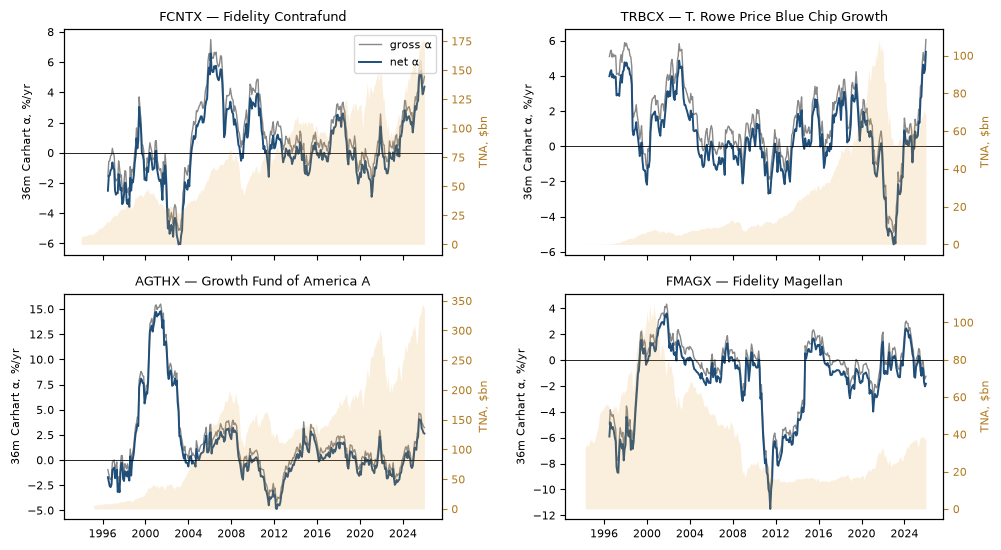

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), sharex=True)
for ax, t in zip(axes.flat, ACTIVE):
    r = roll[roll["ticker"] == t].set_index("date")
    ax.plot(r.index, r["gross"], color="#888888", lw=1, label="gross α")
    ax.plot(r.index, r["net"], color="#1f4e79", lw=1.4, label="net α")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{t} — {NAMES[t]}", fontsize=9)
    ax.set_ylabel("36m Carhart α, %/yr", fontsize=8)
    ax.tick_params(labelsize=8)
    ax2 = ax.twinx()
    s = p[p["ticker"] == t].set_index("date")["tna_m"] / 1e9
    ax2.fill_between(s.index, s.values, color="#e8a33d", alpha=0.18, lw=0)
    ax2.set_ylabel("TNA, $bn", fontsize=8, color="#b07a20")
    ax2.tick_params(labelsize=8, colors="#b07a20")
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig(OUT / "fig1_rolling_alpha_tna.png", dpi=200)
plt.show()

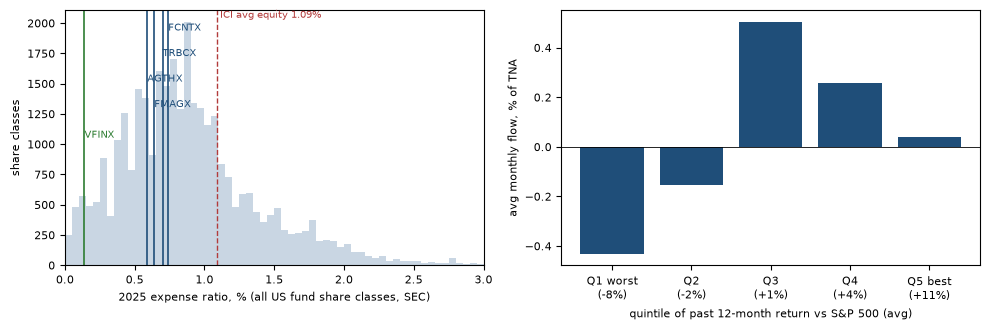

In [24]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.hist(fee_dist * 100, bins=np.arange(0, 3.01, 0.05), color="#c9d6e3")
for t in ACTIVE:
    a1.axvline(fees_2025[t], color="#1f4e79", lw=1.2)
    a1.text(fees_2025[t], a1.get_ylim()[1] * (0.92 - 0.1 * ACTIVE.index(t)), t, fontsize=7, color="#1f4e79")
a1.axvline(fees_2025["VFINX"], color="#2e7d32", lw=1.2)
a1.text(fees_2025["VFINX"], a1.get_ylim()[1] * 0.5, "VFINX", fontsize=7, color="#2e7d32")
a1.axvline(ICI["Average equity fund (simple)"], color="#b23b3b", ls="--", lw=1)
a1.text(ICI["Average equity fund (simple)"], a1.get_ylim()[1] * 0.97, " ICI avg equity 1.09%", fontsize=7, color="#b23b3b")
a1.set_xlabel("2025 expense ratio, % (all US fund share classes, SEC)", fontsize=8)
a1.set_ylabel("share classes", fontsize=8); a1.tick_params(labelsize=8); a1.set_xlim(0, 3)
a2.bar(range(5), flow_bins["avg_monthly_flow_pct"], color="#1f4e79")
a2.set_xticks(range(5))
a2.set_xticklabels([f"{b}\n({v:+.0f}%)" for b, v in zip(flow_bins.index, flow_bins["past12_vs_sp500"])], fontsize=7)
a2.axhline(0, color="black", lw=0.6)
a2.set_ylabel("avg monthly flow, % of TNA", fontsize=8); a2.tick_params(labelsize=8)
a2.set_xlabel("quintile of past 12-month return vs S&P 500 (avg)", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "fig2_fees_flows.png", dpi=200)
plt.show()

### Sensitivity analysis: conclusions

**Two assumptions change verdicts:**
1. **Sample period.** TRBCX's and AGTHX's fees were justified in 1993–2009 but not in 2009–2025, when their gross
   alpha (0.35–0.53%) fell below their fee.
2. **Estimation window.** Net alpha is non-negative in only 50–61% of rolling 36-month windows for the three good
   funds: a three-year track record is close to a coin flip (Figure 1).

**The others leave the verdict unchanged:** the FF3 model and winsorizing (which raises alphas by trimming crash
months) keep the same three funds justified; the index-fund benchmark keeps the signs but makes every net alpha
insignificant; and AGTHX's load (0.59% a year over a 10-year holding, 2.0% over 3 years) leaves its full-sample net
alpha positive only for long holding periods. **Magellan is unjustified under every assumption.**

## 12. Conclusion (requirement 11) and fee design (requirement 12)

| Fund | Verdict | Why |
|---|---|---|
| Contrafund (FCNTX) | **Justified** (most robust) | Positive gross and net alpha in every specification and both halves; part of its CAPM alpha is momentum, and its alpha vs. index funds is not significant |
| Blue Chip Growth (TRBCX) | **Justified 1993–2025, not since 2009** | Real gross alpha early; grew to $108bn and is now close to an expensive growth index fund |
| Growth Fund of America (AGTHX) | **Justified 1993–2025, not since 2009** | Same pattern; grew to $337bn; the 5.75% load makes it unjustified for short holdings |
| Magellan (FMAGX) | **Not justified** | Negative gross alpha under every model and assumption |

**What this means for retail investors and advisors.** Even the best of these funds delivered net alphas that are
statistically indistinguishable from zero against a 0.2% mix of index funds. Past performance barely persists, and the
funds that did well grew until their edge disappeared, as Berk and Green predict. Paying 0.6–0.8% a year for a large
growth fund is hard to justify in advance: a growth or total-market index fund is the sensible default.

**Fee design.**
- A **flat fee on assets** pays the manager for market and growth exposure that costs about 0.2% elsewhere, and it
  grows automatically as flows chase past returns: exactly the Berk and Green mechanism that hands the rents to the
  manager.
- A **simple index-relative bonus** is no better: a growth fund benchmarked to the S&P 500 (as Fidelity's performance
  adjustment is) earns it whenever growth stocks beat the market, without skill (Ch. 15, slides 23–28).
- **Recommendation:** a low base fee near the cost of replicating the fund with index funds (about 0.2–0.25%) plus a
  symmetric 40-Act **fulcrum fee** (Ch. 16, slide 11; Ch. 15, slides 15–16) measured against a factor or style
  benchmark (Ch. 15, slide 27), here the constrained index-fund mix of §8. The manager is paid only for alpha against
  exposures the investor could buy cheaply, and gives back part of the fee when alpha is negative. Absent such a fee,
  advisors should choose the index fund.

**Caveats.**
- *Survivorship and selection bias* (Ch. 16, slides 17–19, 29–30): we chose four famous funds that still exist, so the
  sample leans toward winners; funds that failed were merged away. Magellan shows even famous funds can fail.
- *Incubation bias:* TRBCX's first months follow its 1993 launch, when small new funds often look unusually good.
- *Benchmark choice:* factor portfolios are not free to trade, which is why we also use index funds; neither
  benchmark includes taxes or trading costs.
- *Sample period:* 1993–2025 favoured large growth stocks, which flatters CAPM alphas.
- *Data:* free sources rather than CRSP. Returns were checked against SEC filings, but fees before 2010 are estimates
  from N-SAR (fund-level, all share classes), and with four funds cross-sectional tests have little power.

### Numbers used in the report
These are the numbers quoted in the report. They are saved to `output/summary_numbers.csv`, next to the tables saved above.

In [25]:
summary = {
    "sample": f"{p['date'].min():%Y-%m} to {p['date'].max():%Y-%m} ({p['date'].nunique()} months)",
    "nport_check_median_abs_diff_pp": ret_check["median_abs_diff"].median(),
    "persistence_spearman_halves": rho,
    "persistence_block_slope": persist_block["slope"], "persistence_block_t": persist_block["t"],
    "berk_green_slope": bg_res["slope on log TNA (gross alpha %/yr)"], "berk_green_t": bg_res["t"],
    "tna_rollforward_median_gap_pct": gaps["gap_pct"].abs().median(),
    "index_fee_avg_%": (index_fee * 100).round(3).to_dict(),
    "agthx_load_drag_%": load_drag,
    "fee_dist_median_%": fee_dist.median() * 100,
    "hml_premium_%": ff["hml"].mean() * 1200, "smb_premium_%": ff["smb"].mean() * 1200,
    "umd_premium_%": ff["umd"].mean() * 1200, "mkt_premium_%": ff["mktrf"].mean() * 1200,
    "missing_flow_months": int(act["net_flow"].isna().sum()), "turnover_filled_months": to_fill,
}
pd.Series(summary, dtype=object).to_csv(OUT / "summary_numbers.csv")
pd.Series(summary, dtype=object)

sample                                              1993-07 to 2025-12 (390 months)
nport_check_median_abs_diff_pp                                             0.002215
persistence_spearman_halves                                                     0.2
persistence_block_slope                                                    0.180718
persistence_block_t                                                         1.21478
berk_green_slope                                                          -0.941953
berk_green_t                                                              -1.877904
tna_rollforward_median_gap_pct                                             0.068332
index_fee_avg_%                   {'NAESX': 0.257, 'VFINX': 0.161, 'VIGRX': 0.22...
agthx_load_drag_%                                                          0.590444
fee_dist_median_%                                                              0.82
hml_premium_%                                                              1